<a href="https://colab.research.google.com/github/2403a51078-code/AIDL_LAB_ASSIGNMENTS/blob/main/AIDL_lab_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DEVICE INFORMATION
Using device: cuda
GPU: Tesla T4

LOADING DATASETS
Total training samples: 942
Total testing samples: 943

DATASET SPLIT
Training samples: 848
Validation samples: 94
Testing samples: 943

DATALOADERS CREATED
Training batches: 7
Validation batches: 1
Testing batches: 8

Displaying sample Fashion-MNIST images...


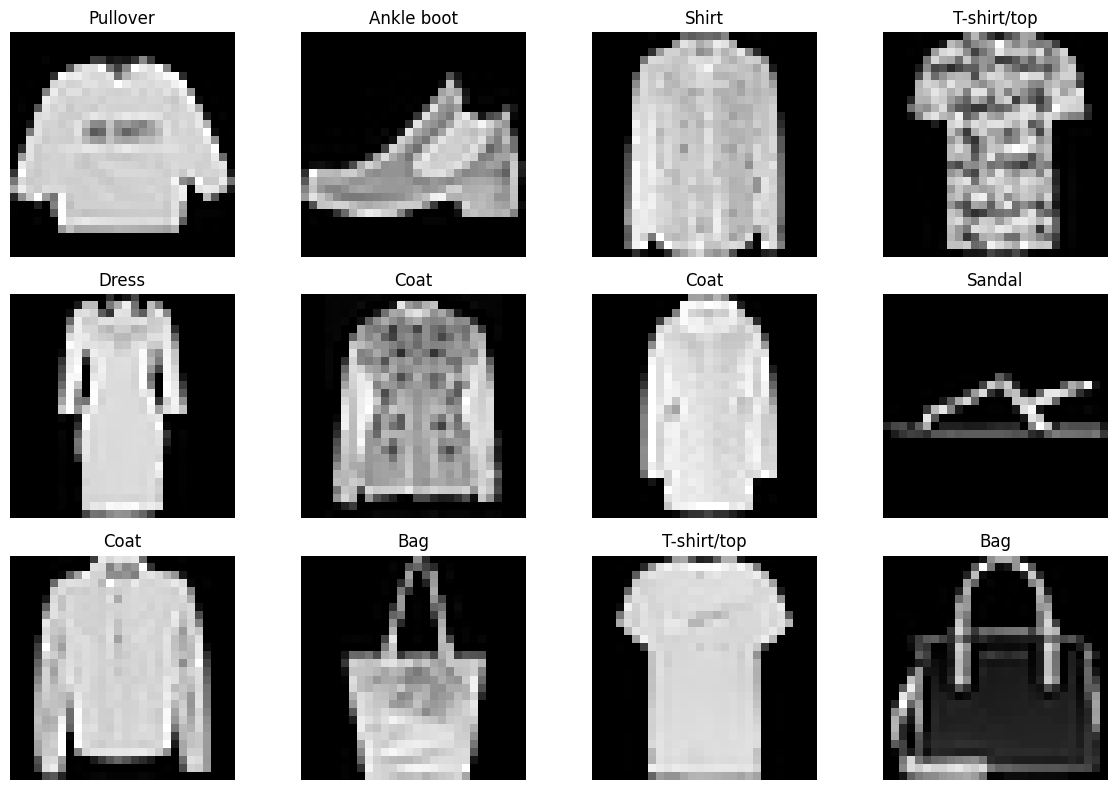

CNN MODEL
FashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=1152, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Trainable parameters: 241994

STARTING TRAINING
Epoch [01/10] | Train Loss: nan | Train Acc: 15.92% | Val Loss: nan | Val Acc: 14.89% | LR: 0.001000
Epoch [02/10] | Train Loss: nan | Train Acc: 10.50% | Val Loss: nan | Val A

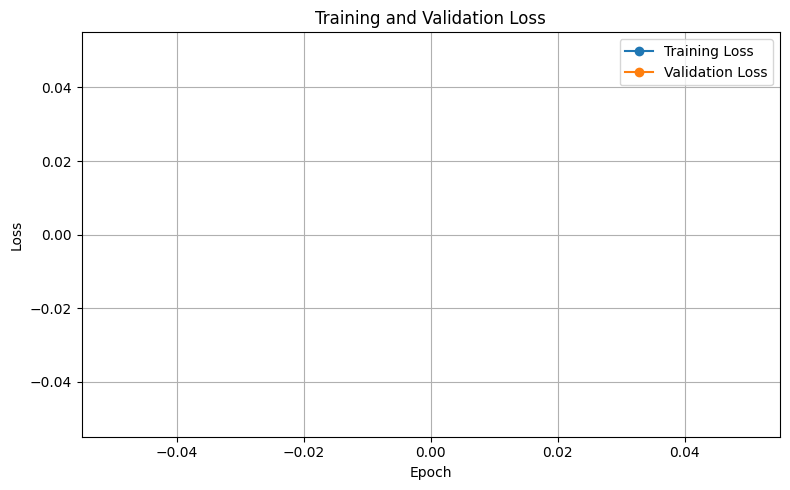

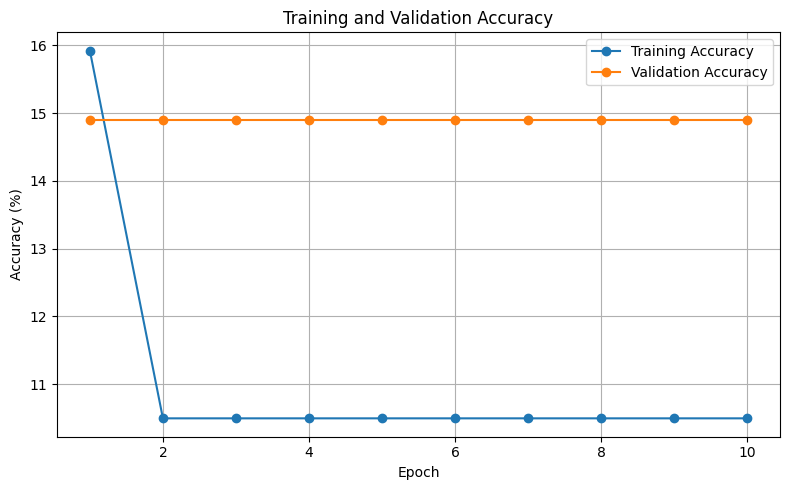

FINAL TEST EVALUATION
Test Loss: nan
Test Accuracy: 9.44%

PERFORMANCE METRICS
Accuracy  : 9.44%
Precision : 0.89%
Recall    : 9.44%
F1 Score  : 1.63%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 T-shirt/top     0.0944    1.0000    0.1725        89
     Trouser     0.0000    0.0000    0.0000        86
    Pullover     0.0000    0.0000    0.0000       103
       Dress     0.0000    0.0000    0.0000        96
        Coat     0.0000    0.0000    0.0000        91
      Sandal     0.0000    0.0000    0.0000        92
       Shirt     0.0000    0.0000    0.0000        94
     Sneaker     0.0000    0.0000    0.0000        98
         Bag     0.0000    0.0000    0.0000        95
  Ankle boot     0.0000    0.0000    0.0000        99

    accuracy                         0.0944       943
   macro avg     0.0094    0.1000    0.0172       943
weighted avg     0.0089    0.0944    0.0163       943



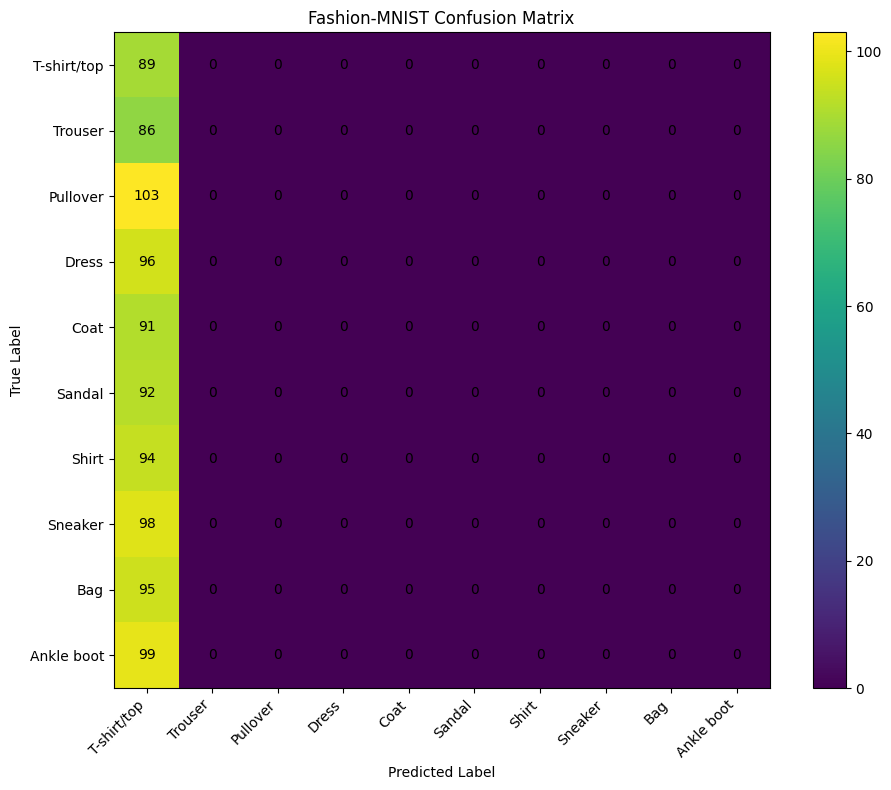

SAMPLE PREDICTIONS


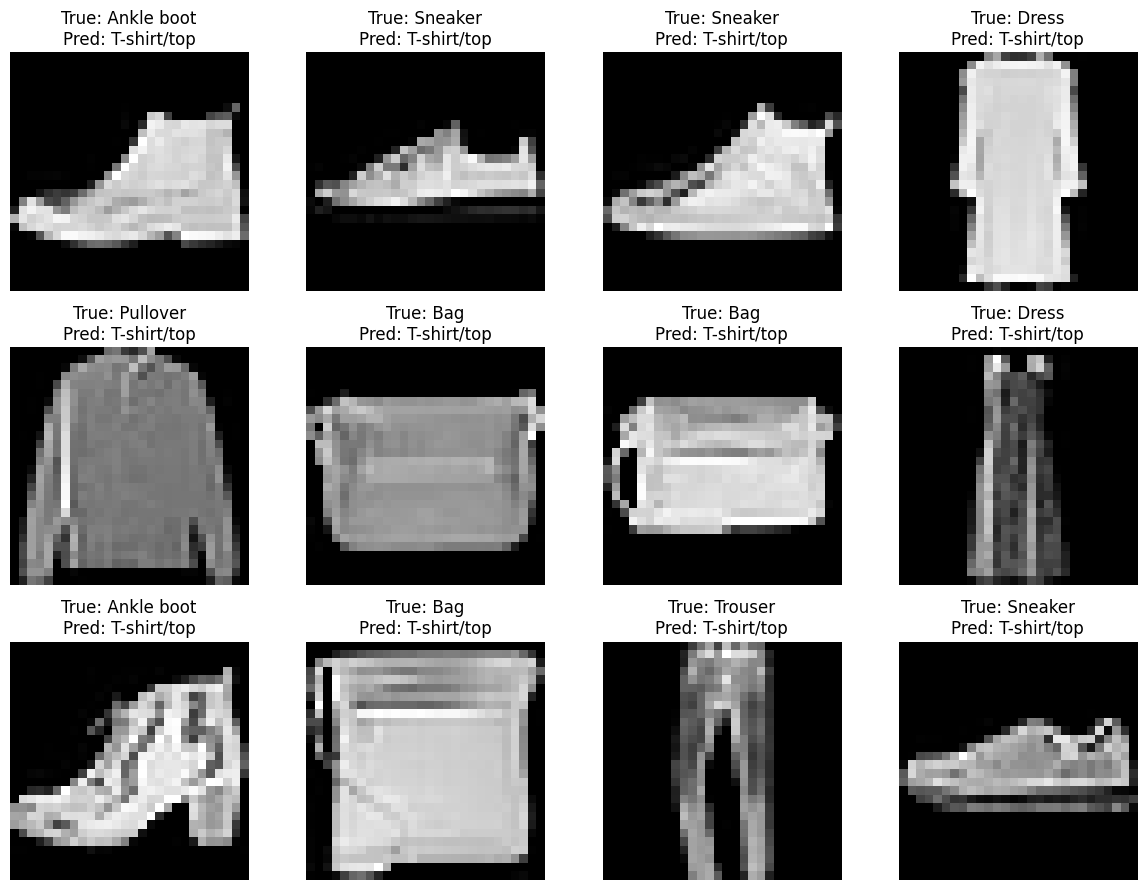

MISCLASSIFIED IMAGES


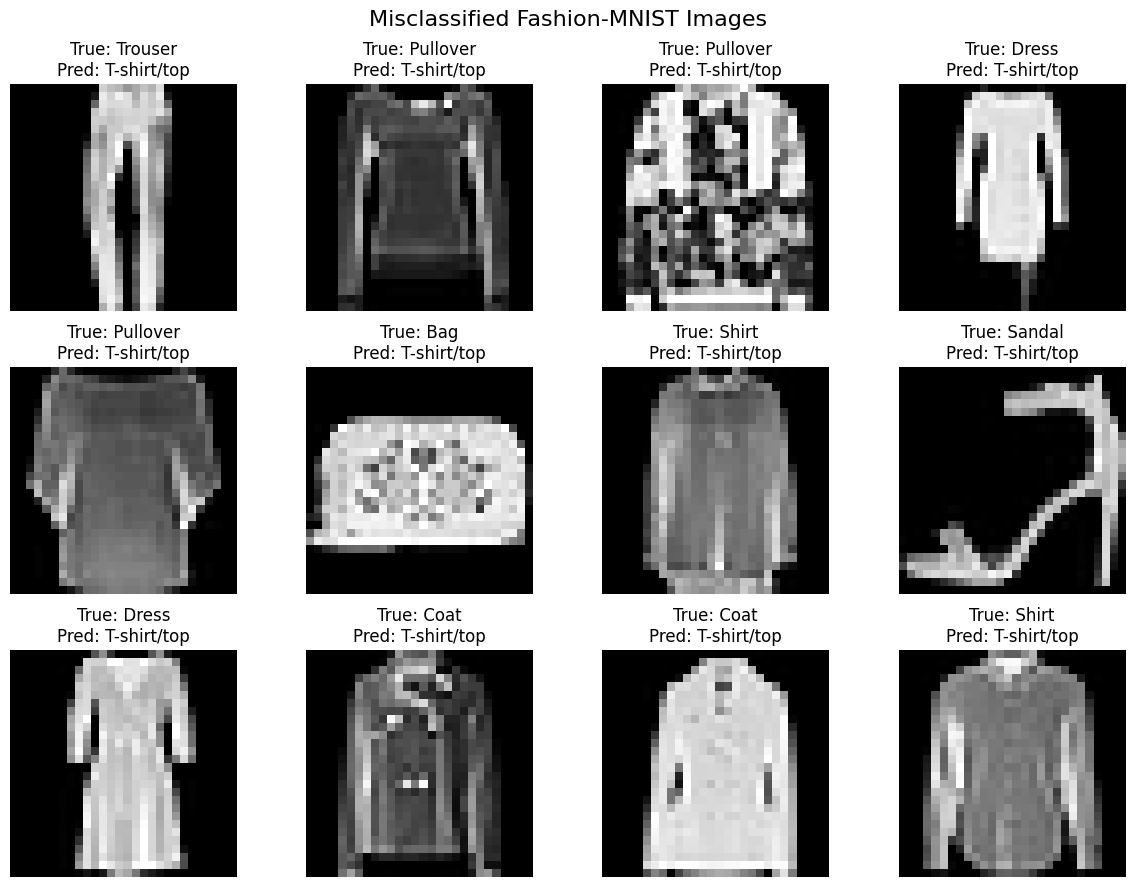

CNN FEATURE MAPS


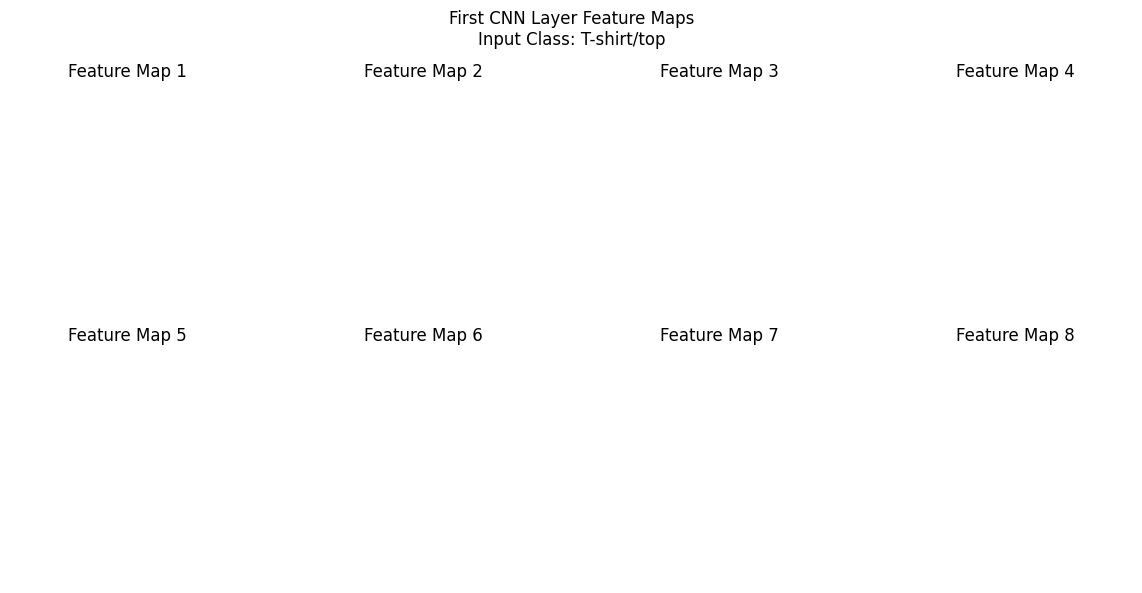

MODEL SAVED
Model saved as: fashion_mnist_cnn_final.pth

EXPERIMENT SUMMARY
Training samples       : 848
Validation samples     : 94
Testing samples        : 943
Batch size             : 128
Learning rate          : 0.001
Number of epochs       : 10
Test loss              : nan
Test accuracy          : 9.44%
Weighted precision     : 0.89%
Weighted recall        : 9.44%
Weighted F1-score      : 1.63%

OBSERVATIONS AND CONCLUSIONS

1. The Fashion-MNIST dataset contains 28x28 grayscale images
   belonging to 10 different clothing categories.

2. The pixel values were normalized from the range [0, 255]
   to [0, 1] before being provided to the CNN.

3. The CNN consists of three convolutional layers followed
   by batch normalization, ReLU activation, max pooling,
   dropout, and fully connected layers.

4. Convolutional layers learn spatial features such as edges,
   shapes, textures, and increasingly complex patterns.

5. Max pooling reduces the spatial dimensions and helps make
   the ne

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Paths to the uploaded CSV files
TRAIN_CSV = "/content/fashion-mnist_train.csv"
TEST_CSV = "/content/fashion-mnist_test.csv"

# Hyperparameters
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 10
VALIDATION_SPLIT = 0.1

# Number of classes in Fashion-MNIST
NUM_CLASSES = 10

# Image dimensions
IMAGE_SIZE = 28

# Random seed for reproducibility
SEED = 42


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Make CUDA operations reproducible where possible
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("DEVICE INFORMATION")
print("=" * 60)
print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print()



class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]


class FashionMNISTCSV(Dataset):

    def __init__(self, csv_file, transform=None):

        self.data = pd.read_csv(csv_file)

        # First column is label
        self.labels = self.data.iloc[:, 0].values

        # Remaining 784 columns are pixels
        self.images = self.data.iloc[:, 1:].values

        self.transform = transform

        # Convert pixel values to float32
        self.images = self.images.astype(np.float32)

        # Normalize pixels from [0, 255] to [0, 1]
        self.images = self.images / 255.0

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        # Get image
        image = self.images[index]

        # Reshape 784 pixels into 28x28
        image = image.reshape(28, 28)

        # Convert to tensor
        image = torch.tensor(image, dtype=torch.float32)

        # Add channel dimension
        # Shape becomes [1, 28, 28]
        image = image.unsqueeze(0)

        label = int(self.labels[index])

        return image, label



print("=" * 60)
print("LOADING DATASETS")
print("=" * 60)

full_train_dataset = FashionMNISTCSV(TRAIN_CSV)
test_dataset = FashionMNISTCSV(TEST_CSV)

print("Total training samples:", len(full_train_dataset))
print("Total testing samples:", len(test_dataset))

print()




validation_size = int(len(full_train_dataset) * VALIDATION_SPLIT)
training_size = len(full_train_dataset) - validation_size

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [training_size, validation_size],
    generator=torch.Generator().manual_seed(SEED)
)

print("=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Testing samples:", len(test_dataset))

print()


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("=" * 60)
print("DATALOADERS CREATED")
print("=" * 60)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))

print()



def show_sample_images(dataset, num_images=12):

    plt.figure(figsize=(12, 8))

    for i in range(num_images):

        image, label = dataset[i]

        plt.subplot(3, 4, i + 1)

        plt.imshow(
            image.squeeze().numpy(),
            cmap="gray"
        )

        plt.title(class_names[label])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


print("Displaying sample Fashion-MNIST images...")

show_sample_images(full_train_dataset)



class FashionCNN(nn.Module):

    def __init__(self):

        super(FashionCNN, self).__init__()



        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.bn1 = nn.BatchNorm2d(32)


        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.bn2 = nn.BatchNorm2d(64)


        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.dropout = nn.Dropout(0.5)

        # 128 * 3 * 3 = 1152

        self.fc1 = nn.Linear(
            128 * 3 * 3,
            128
        )

        self.fc2 = nn.Linear(
            128,
            NUM_CLASSES
        )

    def forward(self, x):

        # First convolution block
        x = self.conv1(x)
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.pool(x)

        # Second convolution block
        x = self.conv2(x)
        x = self.bn2(x)
        x = torch.relu(x)
        x = self.pool(x)

        # Third convolution block
        x = self.conv3(x)
        x = self.bn3(x)
        x = torch.relu(x)
        x = self.pool(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully connected layer
        x = self.fc1(x)
        x = torch.relu(x)

        # Dropout
        x = self.dropout(x)

        # Output layer
        x = self.fc2(x)

        return x



model = FashionCNN().to(device)

print("=" * 60)
print("CNN MODEL")
print("=" * 60)

print(model)

print()


total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_parameters)
print()




criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        # Move data to CPU/GPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * images.size(0)

        # Calculate accuracy
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy




def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

            all_predictions.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        np.array(all_labels),
        np.array(all_predictions)
    )



print("=" * 60)
print("STARTING TRAINING")
print("=" * 60)

train_losses = []
train_accuracies = []

validation_losses = []
validation_accuracies = []

best_validation_accuracy = 0.0

# Save best model
best_model_path = "best_fashion_mnist_cnn.pth"


for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    (
        validation_loss,
        validation_accuracy,
        _,
        _
    ) = evaluate_model(
        model,
        validation_loader,
        criterion
    )

    # Store history
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    validation_losses.append(validation_loss)
    validation_accuracies.append(validation_accuracy)

    # Adjust learning rate
    scheduler.step(validation_loss)

    # Save best model
    if validation_accuracy > best_validation_accuracy:

        best_validation_accuracy = validation_accuracy

        torch.save(
            model.state_dict(),
            best_model_path
        )

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {validation_loss:.4f} | "
        f"Val Acc: {validation_accuracy:.2f}% | "
        f"LR: {current_lr:.6f}"
    )


print()
print("Training completed.")
print("Best validation accuracy:",
      f"{best_validation_accuracy:.2f}%")

print()



model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

print("Best model loaded.")
print()




plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    validation_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    validation_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



print("=" * 60)
print("FINAL TEST EVALUATION")
print("=" * 60)

(
    test_loss,
    test_accuracy,
    true_labels,
    predictions
) = evaluate_model(
    model,
    test_loader,
    criterion
)

print("Test Loss:", f"{test_loss:.4f}")
print("Test Accuracy:", f"{test_accuracy:.2f}%")
print()



precision = precision_score(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

accuracy = accuracy_score(
    true_labels,
    predictions
)

print("=" * 60)
print("PERFORMANCE METRICS")
print("=" * 60)

print(
    f"Accuracy  : {accuracy * 100:.2f}%"
)

print(
    f"Precision : {precision * 100:.2f}%"
)

print(
    f"Recall    : {recall * 100:.2f}%"
)

print(
    f"F1 Score  : {f1 * 100:.2f}%"
)

print()


# ------------------------------------------------------------
# 25. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        true_labels,
        predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)




cm = confusion_matrix(
    true_labels,
    predictions
)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.title("Fashion-MNIST Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    range(NUM_CLASSES),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    class_names
)

# Add values to each cell
for i in range(NUM_CLASSES):

    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()
plt.show()




def visualize_predictions(
    model,
    dataset,
    num_images=12
):

    model.eval()

    plt.figure(figsize=(12, 9))

    # Select random samples
    indices = random.sample(
        range(len(dataset)),
        num_images
    )

    for i, index in enumerate(indices):

        image, true_label = dataset[index]

        # Add batch dimension
        input_image = image.unsqueeze(0).to(device)

        with torch.no_grad():

            output = model(input_image)

            predicted_label = torch.argmax(
                output,
                dim=1
            ).item()

        plt.subplot(3, 4, i + 1)

        plt.imshow(
            image.squeeze().numpy(),
            cmap="gray"
        )

        plt.title(
            f"True: {class_names[true_label]}\n"
            f"Pred: {class_names[predicted_label]}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()


print("=" * 60)
print("SAMPLE PREDICTIONS")
print("=" * 60)

visualize_predictions(
    model,
    test_dataset,
    num_images=12
)



def visualize_misclassified(
    model,
    dataset,
    num_images=12
):

    model.eval()

    wrong_images = []
    wrong_labels = []
    wrong_predictions = []

    with torch.no_grad():

        for i in range(len(dataset)):

            image, true_label = dataset[i]

            input_image = (
                image.unsqueeze(0).to(device)
            )

            output = model(input_image)

            predicted_label = torch.argmax(
                output,
                dim=1
            ).item()

            if predicted_label != true_label:

                wrong_images.append(image)
                wrong_labels.append(true_label)
                wrong_predictions.append(predicted_label)

            if len(wrong_images) >= num_images:
                break

    if len(wrong_images) == 0:

        print("No misclassified images found.")

        return

    plt.figure(figsize=(12, 9))

    for i in range(len(wrong_images)):

        plt.subplot(3, 4, i + 1)

        plt.imshow(
            wrong_images[i].squeeze().numpy(),
            cmap="gray"
        )

        plt.title(
            f"True: {class_names[wrong_labels[i]]}\n"
            f"Pred: {class_names[wrong_predictions[i]]}"
        )

        plt.axis("off")

    plt.suptitle(
        "Misclassified Fashion-MNIST Images",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


print("=" * 60)
print("MISCLASSIFIED IMAGES")
print("=" * 60)

visualize_misclassified(
    model,
    test_dataset,
    num_images=12
)


def visualize_feature_maps(
    model,
    dataset,
    num_features=8
):

    model.eval()

    image, label = dataset[0]

    input_image = (
        image.unsqueeze(0).to(device)
    )

    # Get activations from first convolution
    with torch.no_grad():

        feature_maps = model.conv1(
            input_image
        )

        feature_maps = torch.relu(
            feature_maps
        )

    feature_maps = feature_maps.squeeze(0).cpu()

    plt.figure(figsize=(12, 6))

    for i in range(
        min(num_features, feature_maps.shape[0])
    ):

        plt.subplot(2, 4, i + 1)

        plt.imshow(
            feature_maps[i],
            cmap="viridis"
        )

        plt.title(
            f"Feature Map {i + 1}"
        )

        plt.axis("off")

    plt.suptitle(
        f"First CNN Layer Feature Maps\n"
        f"Input Class: {class_names[label]}"
    )

    plt.tight_layout()
    plt.show()


print("=" * 60)
print("CNN FEATURE MAPS")
print("=" * 60)

visualize_feature_maps(
    model,
    test_dataset,
    num_features=8
)



final_model_path = "fashion_mnist_cnn_final.pth"

torch.save(
    model.state_dict(),
    final_model_path
)

print("=" * 60)
print("MODEL SAVED")
print("=" * 60)

print(
    "Model saved as:",
    final_model_path
)

print()



print("=" * 60)
print("EXPERIMENT SUMMARY")
print("=" * 60)

print(
    f"Training samples       : {len(train_dataset)}"
)

print(
    f"Validation samples     : {len(validation_dataset)}"
)

print(
    f"Testing samples        : {len(test_dataset)}"
)

print(
    f"Batch size             : {BATCH_SIZE}"
)

print(
    f"Learning rate          : {LEARNING_RATE}"
)

print(
    f"Number of epochs       : {NUM_EPOCHS}"
)

print(
    f"Test loss              : {test_loss:.4f}"
)

print(
    f"Test accuracy          : {test_accuracy:.2f}%"
)

print(
    f"Weighted precision     : {precision * 100:.2f}%"
)

print(
    f"Weighted recall        : {recall * 100:.2f}%"
)

print(
    f"Weighted F1-score      : {f1 * 100:.2f}%"
)

print()


print("=" * 60)
print("OBSERVATIONS AND CONCLUSIONS")
print("=" * 60)

print("""
1. The Fashion-MNIST dataset contains 28x28 grayscale images
   belonging to 10 different clothing categories.

2. The pixel values were normalized from the range [0, 255]
   to [0, 1] before being provided to the CNN.

3. The CNN consists of three convolutional layers followed
   by batch normalization, ReLU activation, max pooling,
   dropout, and fully connected layers.

4. Convolutional layers learn spatial features such as edges,
   shapes, textures, and increasingly complex patterns.

5. Max pooling reduces the spatial dimensions and helps make
   the network more computationally efficient.

6. Dropout is used to reduce overfitting.

7. The Adam optimizer was used because it generally provides
   fast and stable convergence for CNN image classification.

8. CrossEntropyLoss was used because this is a multi-class
   classification problem.

9. Training and validation loss/accuracy curves can be used
   to determine whether the model is learning effectively
   or overfitting.

10. The confusion matrix shows which Fashion-MNIST classes are
    most frequently confused by the CNN.

11. Some classes, such as shirts, T-shirts, pullovers and coats,
    can be visually similar, which can result in classification
    errors.

12. Overall, CNNs are well suited for Fashion-MNIST because
    convolutional layers can automatically learn useful spatial
    features from images.
""")

print("=" * 60)
print("END OF EXPERIMENT")
print("=" * 60)